# Predictive Maintenance Using Machine Learning

##Data Preparation

### Research Question:
Can operational measurements be used to predict industrial equipment failure?

### Dataset:
AI4I 2020 Predictive Maintenance Dataset — UCI Machine Learning Repository.

The dataset contains 10,000 synthetic observations of industrial equipment operating conditions.

### Objectives:
1. Select suitable predictor variables.
2. Prevent target leakage.
3. Split the dataset into training and testing sets.
4. Preserve class proportions using stratified sampling.
5. Prepare a preprocessing pipeline for subsequent model training.

The dataset is synthetic, so model performance will be evaluated as a benchmark rather than evidence of real-world industrial deployment.

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

df = pd.read_csv("ai4i2020.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:

#numerical sensor measurements
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

#categorical features
categorical_features = ["Type"]

#predictor variables
X = df[numerical_features + categorical_features]

#target variable
y = df["Machine failure"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Predictor shape: (10000, 6)
Target shape: (10000,)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type
0,298.1,308.6,1551,42.8,0,M
1,298.2,308.7,1408,46.3,3,L
2,298.1,308.5,1498,49.4,5,L
3,298.2,308.6,1433,39.5,7,L
4,298.2,308.7,1408,40.0,9,L


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))


Training observations: 8000
Testing observations: 2000


In [6]:

print("Original failure rate:")
print(f"{y.mean() * 100:.2f}%")

print("\nTraining failure rate:")
print(f"{y_train.mean() * 100:.2f}%")

print("\nTesting failure rate:")
print(f"{y_test.mean() * 100:.2f}%")

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())


Original failure rate:
3.39%

Training failure rate:
3.39%

Testing failure rate:
3.40%

Training class counts:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing class counts:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [7]:

# Define preprocessing for numerical variables
numeric_transformer = StandardScaler()

# Define preprocessing for categorical variables
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


## Data Preparation Methodology

The predictive features consist of five numerical operating measurements and one categorical machine-type variable.

The failure-type indicators (TWF, HDF, PWF, OSF and RNF) were excluded to prevent direct target leakage. UDI and Product ID were excluded because they are identifiers rather than operational measurements.

The dataset was divided into 80% training and 20% testing observations using stratified random sampling. Stratification was used to preserve the low machine failure rate across both subsets.

Numerical features will be standardized using StandardScaler, while the machine-type category will be encoded using OneHotEncoder.

Pre-processing will be fitted exclusively on the training data through a scikit-learn Pipeline during model development.

The held out test set will remain unused during model selection and tuning to provide a less biased final evaluation.

This aproach supports benchmark evaluation, eventhough a random split of synthetic observations does not re-inforce real world predictive performance.

Objective:

Develop a baseline classification model for predicting machine failure using operational sensor measurements.

Model performance will be assessed using stratified cross-validation on the training set. The held-out test set will be reserved for final evaluation after model selection.

Due to the low failure rate, precision, recall, F1-score, and average precision will be considered alongside accuracy.

In [8]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

#create a reproducible validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#combine pre-processing and classification
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

#evaluate using only trainng data
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "average_precision": "average_precision"
}

logistic_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Logistic Regression — Cross-Validation Results")

for metric in scoring:
    values = logistic_cv[f"test_{metric}"]
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")


Logistic Regression — Cross-Validation Results
accuracy: 0.970 ± 0.001
precision: 0.761 ± 0.109
recall: 0.199 ± 0.028
f1: 0.312 ± 0.026
average_precision: 0.469 ± 0.032


In [9]:

logistic_model.fit(X_train, y_train)

print("Logistic regression trained successfully.")
print("Training observations:", len(X_train))


Logistic regression trained successfully.
Training observations: 8000


In [10]:

import pandas as pd

logistic_results = {
    "Model": "Logistic regression"
}

for metric in scoring:
    logistic_results[metric] = logistic_cv[
        f"test_{metric}"
    ].mean()

logistic_results_df = pd.DataFrame([logistic_results])

display(logistic_results_df.round(3))


,Model,accuracy,precision,recall,f1,average_precision
0,Logistic regression,0.97,0.761,0.199,0.312,0.469


### Logistic Regression: Initial findings

A logistic regression classifier was trained using a preprocessing pipeline and evaluated through five-fold stratified cross-validation on the training dataset.The model achieved a mean accuracy of 97.0%, precision of 76.1%, recall of 19.9%, F1-score of 31.2%, and Average Precision of 0.469.

Although overall accuracy was high, the recall was relatively low which indicated that the classifier failed to identify approximately 80% of actual machine failures at the default classification threshold.

This highlights the limitations of accuracy as an evaluation metric for imbalanced classification problems.

The relatively high precision suggests that the model's positive predictions were often correct. However, the low recall limits its usefulness for applications where undetected equipment failures are costly.

The Average precision score suggests that the model provides basic ability to rank observations by failure risk, even though its default classification threshold detects only relatively few failures.

These findings motivate comparison with a more flexible nonlinear classifier, such as Random Forest, and further investigation of alternative classification thresholds.

Objective:

Develop a Random Forest classifier to investigate whether a nonlinear machine learning model can improve predictive performance compared with Logistic Regression.

The Random Forest will be evaluated using the same stratified cross-validation strategy and metrics to ensure a consistent comparison. The held-out test dataset will remain unused until final model evaluation.

In [11]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

#create Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ))
])

#evaluate using the same five fold cross validation
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest — Cross-Validation Results")

for metric in scoring:
    values = rf_cv[f"test_{metric}"]
    print(
        f"{metric}: "
        f"{values.mean():.3f} ± {values.std():.3f}"
    )


Random Forest — Cross-Validation Results
accuracy: 0.980 ± 0.002
precision: 0.874 ± 0.029
recall: 0.480 ± 0.048
f1: 0.618 ± 0.040
average_precision: 0.770 ± 0.022


In [12]:

rf_results = {
    "Model": "Random Forest"
}

for metric in scoring:
    rf_results[metric] = rf_cv[
        f"test_{metric}"
    ].mean()

rf_results_df = pd.DataFrame([rf_results])

comparison_df = pd.concat(
    [logistic_results_df, rf_results_df],
    ignore_index=True
)

display(comparison_df.round(3))


,Model,accuracy,precision,recall,f1,average_precision
0,Logistic regression,0.97,0.761,0.199,0.312,0.469
1,Random Forest,0.98,0.874,0.480,0.618,0.770


### Random Forest: Model comparison findings

A Random Forest classifier with 200 decision trees was evaluated using five-fold stratified cross-validation on the training dataset. The model achieved an average accuracy of 98.0%, precision of 87.4%, recall of 48.0%, F1-score of 0.618, and Average Precision of 0.770.

Compared with Logistic Regression, Random Forest demonstrated improvements across all five evaluation metrics. The most significant improvement was in recall, which increased from 19.9% to 48.0%. This indicates that Random Forest detected a substantially greater proportion of machine failures at the default classification threshold.

Average Precision also improved from 0.469 to 0.770, suggesting stronger discrimination between higher-risk and lower-risk observations across classification thresholds.

These results are consistent with the possibility that nonlinear relationships and feature interactions are important for predicting failures in the synthetic AI4I dataset.

However, the Random Forest still missed approximately 52% of failures at the default classification threshold. Further investigation of decision thresholds is therefore warranted. Based on the cross-validation results, Random Forest was selected for further evaluation. The held-out test set has not yet been used.

Objective:

Investigating whether adjusting the Random Forest classification threshold can improve machine failure detection.The threshold selection will be performed using out-of-fold predictions from the training dataset.

The held-out test dataset will not be used until the threshold has been selected. The analysis will examine the trade-off between precision and recall and evaluate whether a lower classification threshold provides a more appropriate balance for predictive maintenance.

In [14]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

#generate outof fold failure probabilities
rf_oof_prob = cross_val_predict(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions generated.")
print("Number of predictions:", len(rf_oof_prob))


Out-of-fold predictions generated.
Number of predictions: 8000


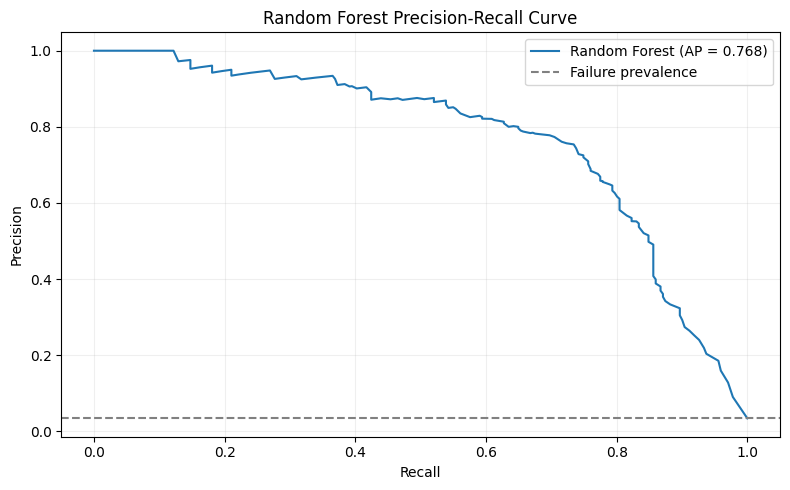

In [15]:

from sklearn.metrics import average_precision_score

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_train, rf_oof_prob)
)

oof_ap = average_precision_score(
    y_train,
    rf_oof_prob
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    recall_values,
    precision_values,
    label=f"Random Forest (AP = {oof_ap:.3f})"
)

ax.axhline(
    y_train.mean(),
    linestyle="--",
    color="gray",
    label="Failure prevalence"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Random Forest Precision-Recall Curve")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [16]:

import numpy as np

#calculate F1 for each available threshold
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (
        precision_values[:-1]
        + recall_values[:-1]
        + 1e-12
    )
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print(f"Selected threshold: {best_threshold:.3f}")
print(f"Out of fold F1: {f1_values[best_index]:.3f}")
print(f"Precision: {precision_values[best_index]:.3f}")
print(f"Recall: {recall_values[best_index]:.3f}")


Selected threshold: 0.305
Out of fold F1: 0.744
Precision: 0.754
Recall: 0.734


### Classification threshold analysis: Findings

The Random Forest classifier was further investigated using out of fold predicted probabilities generated through five-fold stratified cross-validation.

The precision recall curve produced an Average Precision score of 0.768, indicating that the classifier ranked failure observations  better than the baseline failure prevalence of approximately 3.39%.

The classification threshold was adjusted from the default value of 0.50 to 0.305 by maximizing F1-score on the out-of-fold predictions.

At the selected threshold, precision was 0.754, recall was 0.734, and F1-score was 0.744.

Compared with the default-threshold cross-validation results, the selected threshold demonstrated a more favourable balance between precision and recall, particularly for detecting machine failures.

However, threshold selection and evaluation were performed using the same out-of-fold predictions, so these results may be optimistic.The selected threshold will be evaluated on the previously untouched test dataset to assess generalized performance.

In [17]:

#Random Forest on the full training set
rf_model.fit(X_train, y_train)

print("Final Random Forest model trained.")
print("Training observations:", len(X_train))


Final Random Forest model trained.
Training observations: 8000


In [18]:

#predict failure probabilities
test_probabilities = rf_model.predict_proba(X_test)[:, 1]

#apply the previously selected threshold
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Test observations:", len(test_predictions))
print("Predicted failures:", test_predictions.sum())


Test observations: 2000
Predicted failures: 69


In [19]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report
)

final_accuracy = accuracy_score(y_test, test_predictions)
final_precision = precision_score(
    y_test, test_predictions, zero_division=0
)
final_recall = recall_score(
    y_test, test_predictions, zero_division=0
)
final_f1 = f1_score(
    y_test, test_predictions, zero_division=0
)
final_ap = average_precision_score(
    y_test, test_probabilities
)

print("FINAL HELD OUT TEST RESULTS")
print(f"Accuracy:          {final_accuracy:.3f}")
print(f"Precision:         {final_precision:.3f}")
print(f"Recall:            {final_recall:.3f}")
print(f"F1-score:          {final_f1:.3f}")
print(f"Average Precision: {final_ap:.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)


FINAL HELD OUT TEST RESULTS
Accuracy:          0.982
Precision:         0.725
Recall:            0.735
F1-score:          0.730
Average Precision: 0.789

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.72      0.74      0.73        68

    accuracy                           0.98      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.98      0.98      0.98      2000



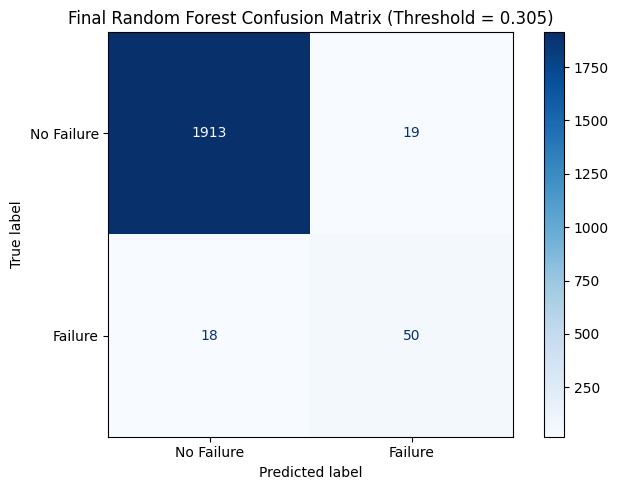

In [24]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No Failure", "Failure"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    f"Final Random Forest Confusion Matrix "
    f"(Threshold = {best_threshold:.3f})"
)

plt.tight_layout()
plt.show()


In [20]:

final_results = pd.DataFrame([{
    "Model": "Random Forest",
    "Threshold": best_threshold,
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1-score": final_f1,
    "Average Precision": final_ap
}])

display(final_results.round(3))

final_results.to_csv(
    "final_model_results.csv",
    index=False
)


,Model,Threshold,Accuracy,Precision,Recall,F1-score,Average Precision
0,Random Forest,0.305,0.982,0.725,0.735,0.73,0.789


## Final Model Evaluation:

The selected Random Forest classifier was evaluated on a held out test dataset containing 2,000 observations, including 68 machine failures.

The classification threshold of 0.305 was selected using out of fold predictions from the training dataset before the final test evaluation.

### Test Results:

- Accuracy: 98.2%
- Precision: 72.5%
- Recall: 73.5%
- F1-score: 0.730
- Average Precision: 0.789

The model correctly identified approximately 73.5% of machine failures while maintaining a precision of 72.5%.

The held-out F1-score of 0.730 was close to the out-of-fold threshold-selection F1-score of 0.744, suggesting that the selected model and threshold performed similarly on this test split. However approximately 26.5% of actual failures were not detected. This remains an important limitation for predictive maintenance applications where missed failures may result in costly downtime.

Although the model achieved high overall accuracy, recall, precision, F1-score and Average Precision provide a more informative assessment because machine failures represent only 3.39% of the dataset.

The results demonstrate predictive performance on a synthetic benchmark dataset. They do not establish that the model would generalize to real industrial equipment without further validation.

In [21]:

from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.base import clone

#create a separate interpretation split from training data
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=123
)

#train a fresh copy of the selected model
interpretation_model = clone(rf_model)
interpretation_model.fit(X_fit, y_fit)

#calculate importance on validation observations
importance = permutation_importance(
    interpretation_model,
    X_valid,
    y_valid,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.round(3))


,Feature,Importance,Std
3,Torque [Nm],0.580,0.017
2,Rotational speed [rpm],0.382,0.032
0,Air temperature [K],0.381,0.033
4,Tool wear [min],0.236,0.019
1,Process temperature [K],0.182,0.020
5,Type,0.067,0.013


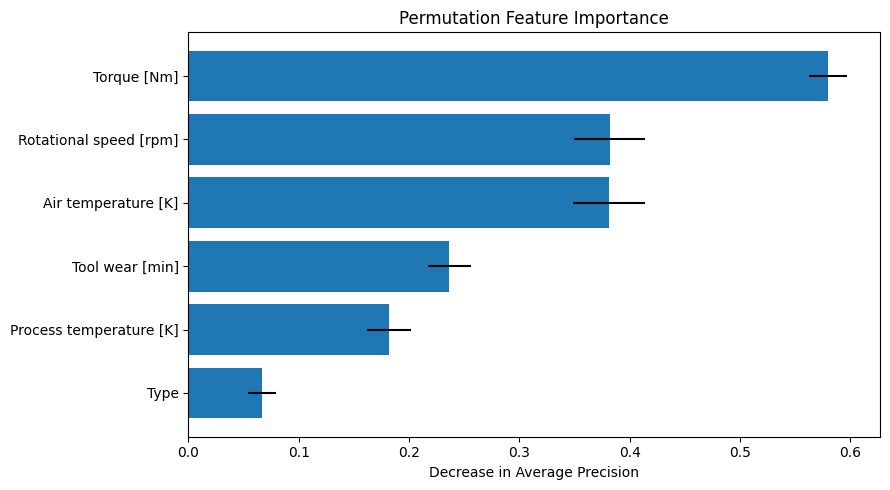

In [22]:

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"]
)

ax.invert_yaxis()
ax.set_xlabel("Decrease in Average Precision")
ax.set_title("Permutation Feature Importance")

plt.tight_layout()
plt.show()


## Feature Importance Analysis:

Permutation importance was used to investigate the contribution of individual predictor variables to the Random Forest classifier.

A separate stratified validation subset was created from the training data, and a fresh Random Forest model was fitted without using the held-out test set.

Feature importance was measured by randomly permuting each feature and calculating the resulting decrease in Average Precision.

### Results:

Torque exhibited the highest permutation importance (0.580), followed by rotational speed (0.382) and air temperature (0.381).

Tool wear (0.236) and process temperature (0.182) also contributed to predictive performance, while machine type had the lowest measured importance (0.067).

These results suggest that mechanical operating conditions, particularly torque and rotational speed, contain important information for distinguishing failure observations from normal operation.

The findings are consistent with the earlier exploratory analysis, which identified a strong negative correlation between torque and rotational speed.

### Limitations:

Permutation importance measures changes in predictive performance when feature values are disrupted. It does not establish causal relationships.

Furthermore, correlated predictors may share information, making individual importance estimates difficult to interpret independently.

The importance values were obtained using a validation subset of a synthetic benchmark dataset and should not be assumed to generalize directly to real industrial equipment.

# Final Conclusions

This project investigated machine failure prediction using the synthetic AI4I 2020 Predictive Maintenance Dataset.

Two machine learning classifiers, Logistic Regression and Random Forest, were evaluated using five-fold stratified cross-validation.

Random Forest achieved stronger cross-validation performance across the evaluated metrics. Its classification threshold was subsequently adjusted to 0.305 using out-of-fold training predictions.

### Final Test Performance:

- **Accuracy:** 98.2%
- **Precision:** 72.5%
- **Recall:** 73.5%
- **F1-score:** 0.730
- **Average Precision:** 0.789

The final model correctly detected 50 of the 68 failures in the held-out test set, while missing 18 failures.

Permutation importance analysis identified torque as the most influential feature in the validation experiment, followed by rotational speed and air temperature.

### Limitations:

The dataset is synthetic, and the results do not establish performance on real industrial equipment.

The model still missed approximately 26.5% of failures. Additionally, the random train-test split does not assess performance on future observations or entirely new machines.

Threshold selection was performed using out-of-fold training predictions, meaning the optimized training F1-score may be optimistic.